# Validating the logical gates on an analytically tractable example

The companion notebook `analytic_posterior_2_classes.ipynb` checks that the **online class
posterior** can be tracked exactly during generation. This one uses that posterior to build the
**AND, OR and NOT gates**, and checks that each one samples from the distribution it is supposed
to.

The construction rules, with $p(c_i\mid x_t)$ the online posterior:

$$R^{\mathrm{OR}} = \sum_i p(c_i\mid x_t)\,R^{c_i},
\qquad
R^{\mathrm{NOT}} = R^{\emptyset} - \frac{p(c\mid x_t)}{1 - p(c\mid x_t)}\bigl(R^{c} - R^{\emptyset}\bigr).$$

OR arbitrates between its conditions by their posteriors; NOT activates a repulsive term only
when the forbidden class is actually being approached. AND is multiplicative and is built at the
data level — see the AND section below.

**Four classes, so that they overlap.** Two classes that differ over the whole sequence are
mutually exclusive, which makes AND empty. Here the sequence is split into two halves and each
class constrains only one of them, leaving the other uniform — so `A1` (first half mostly A) and
`B2` (second half mostly B) are perfectly compatible and AND(`A1`, `B2`) is a real distribution.

**How the check works.** Comparing full sequences would need far too many samples, so each
sequence is reduced to the counts $(n_1, n_2)$ of A-tokens in each half. Every target here depends
on a sequence only through those counts, so the exact target distribution over $(n_1, n_2)$ is
available in closed form, and we can measure the KL between it and the empirical distribution of
generated samples — not only at the end, but at every noise level along the trajectory.

## The data: four classes, each constraining one half

Sequences are $L = 20$ tokens over $\{\mathrm{A}, \mathrm{B}\}$, split into
$\mathcal{H}_1 = $ positions $0\!:\!10$ and $\mathcal{H}_2 = $ positions $10\!:\!20$. Each class
makes one half lean towards a token with probability $p_{\mathrm{maj}} = 0.85$ and leaves the
other half uniform:

| class | $\mathcal{H}_1$ | $\mathcal{H}_2$ |
|-------|-----------------|-----------------|
| `A1`  | $p(\mathrm{A}) = p_{\mathrm{maj}}$ | uniform |
| `A2`  | uniform | $p(\mathrm{A}) = p_{\mathrm{maj}}$ |
| `B1`  | $p(\mathrm{A}) = 1 - p_{\mathrm{maj}}$ | uniform |
| `B2`  | uniform | $p(\mathrm{A}) = 1 - p_{\mathrm{maj}}$ |

All positions are independent within a class, so every class is a complete generative law over
the whole sequence and every sequence has non-zero likelihood under all four. The unconditional
model is the equal-weight mixture.

`NOISE_TYPE` switches the whole notebook between masking and uniform corruption; the Figure 7
cell runs both regardless.

In [11]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)   # notebook-wide: use double precision throughout

# ---- Noise type -- the single toggle that switches the whole notebook ----
NOISE_TYPE     = 'uniform'   # 'uniform' | 'masking'
SCHEDULER_TYPE = 'linear'
num_steps      = 500

# ---- Sequence / vocab settings ----
L = 20
if NOISE_TYPE == 'masking':
    VOCAB_SIZE = 3            # A=0, B=1, MASK=2
    MASK       = VOCAB_SIZE - 1
else:
    VOCAB_SIZE = 2             # A=0, B=1 -- no MASK token under uniform diffusion
    MASK       = None
HALF1, HALF2 = slice(0, 10), slice(10, 20)

# ---- Separability knob ----
P_MAJ = 0.85               # > 0.5; probability of the dominant token in a "structured" half

# ---- Transition-kernel choice (uniform diffusion has two genuinely different kernels; see
#      the markdown cell below). Under masking the two coincide, so both are forced to 'dfm'. ----
SAMPLING_KERNEL  = 'ancestral' if NOISE_TYPE == 'uniform' else 'dfm'   # 'dfm' | 'ancestral' -- kernel used to draw x_next during sampling
POSTERIOR_KERNEL = 'ancestral' if NOISE_TYPE == 'uniform' else 'dfm'   # 'dfm' | 'ancestral' -- kernel used to score transitions for posterior tracking (S / tracked_posts)

CLASS_NAMES = ['A1', 'A2', 'B1', 'B2']
NUM_CLASSES = 4

# Q[c, j] = P(x_0^j = A | class c)  --  fully specifies each class's i.i.d. per-position law
Q = np.full((NUM_CLASSES, L), 0.5)
Q[0, HALF1] = P_MAJ          # A1: HALF1 A-dominant, HALF2 flat
Q[1, HALF2] = P_MAJ          # A2: HALF2 A-dominant, HALF1 flat
Q[2, HALF1] = 1 - P_MAJ      # B1: HALF1 B-dominant, HALF2 flat
Q[3, HALF2] = 1 - P_MAJ      # B2: HALF2 B-dominant, HALF1 flat
Q = torch.from_numpy(Q).double()   # [NUM_CLASSES, L]

print(f'NOISE_TYPE={NOISE_TYPE!r}, L={L} (HALF1=0:10, HALF2=10:20), VOCAB_SIZE={VOCAB_SIZE}, P_MAJ={P_MAJ}')
print(f'SAMPLING_KERNEL={SAMPLING_KERNEL!r}, POSTERIOR_KERNEL={POSTERIOR_KERNEL!r}')
print('Classes:', CLASS_NAMES)
print('Q[c, j] = P(x_0^j=A | c):')
for c in range(NUM_CLASSES):
    print(f'  {CLASS_NAMES[c]}: HALF1={Q[c, HALF1][0].item():.2f}  HALF2={Q[c, HALF2][0].item():.2f}')

NOISE_TYPE='uniform', L=20 (HALF1=0:10, HALF2=10:20), VOCAB_SIZE=2, P_MAJ=0.85
SAMPLING_KERNEL='ancestral', POSTERIOR_KERNEL='ancestral'
Classes: ['A1', 'A2', 'B1', 'B2']
Q[c, j] = P(x_0^j=A | c):
  A1: HALF1=0.85  HALF2=0.50
  A2: HALF1=0.50  HALF2=0.85
  B1: HALF1=0.15  HALF2=0.50
  B2: HALF1=0.50  HALF2=0.15


## Corruption, kernels and the denoising step

Both noise types share the schedule $\kappa_t$. Masking sends a corrupted position to an
absorbing `MASK`; uniform sends it to a random token, so positions keep changing. Uniform noise
admits two reverse kernels — the ancestral (exact reverse, D3PM/MD4) and the ODE-style `dfm` step
— and they coincide under masking.

In [12]:
def to_one_hot(x, vocab_size):
    return F.one_hot(x.long(), num_classes=vocab_size).double()


def get_scheduler(t, scheduler_type='linear'):
    if not isinstance(t, torch.Tensor):
        t = torch.tensor(t, dtype=torch.float64)
    if scheduler_type == 'linear':
        return t, torch.ones_like(t)
    if scheduler_type == 'cosine':
        kappa     = 1 - torch.cos(torch.pi / 2 * t)
        kappa_dot = torch.pi / 2 * torch.sin(torch.pi / 2 * t)
        return kappa, kappa_dot
    raise ValueError(f'Unknown scheduler_type: {scheduler_type}')


def noising_sequences(x_clean, t, vocab_size, scheduler_type='linear'):
    """Corrupt a clean batch under the global NOISE_TYPE: replace corrupted positions with
    MASK (masking) or an independent uniform-random token (uniform)."""
    kappa_t, _ = get_scheduler(t, scheduler_type)
    corruption_prob = (1 - kappa_t).view(-1, 1).expand_as(x_clean).double()
    corrupted_mask = torch.bernoulli(corruption_prob).bool()
    x_noisy = x_clean.clone()
    if NOISE_TYPE == 'masking':
        x_noisy[corrupted_mask] = vocab_size - 1
    else:
        random_tokens = torch.randint(0, vocab_size, x_clean.shape)
        x_noisy[corrupted_mask] = random_tokens[corrupted_mask]
    return x_noisy, corrupted_mask


def get_masked_tokens(x, vocab_size):
    """masking only: which positions are still MASK (i.e. not yet revealed)."""
    return x == (vocab_size - 1)


def init_state(batch_size):
    """t=0 starting state: all-MASK under masking diffusion, pure uniform noise under
    uniform diffusion."""
    if NOISE_TYPE == 'masking':
        return torch.full((batch_size, L), MASK, dtype=torch.long)
    return torch.randint(0, VOCAB_SIZE, (batch_size, L))


def build_transition_distr(x_pred, x_one_hot, kappa_t, kappa_t_next, kernel='dfm'):
    """kernel='dfm' -- ODE-style DFM transition formula, identical for both noise types; see
    `compute_transition_distr` in src/discrete_flow_matching/sampling/sampling_images.py.
    kernel='ancestral' -- MD4 CTMC ancestral kernel (uniform diffusion only; same source
    function, `use_ancestral_sampling_probs=True` branch), a genuinely different reverse process
    from the DFM ODE step (they coincide for masking, but not for uniform noise -- which is why
    `SAMPLING_KERNEL`/`POSTERIOR_KERNEL` are forced to 'dfm' whenever NOISE_TYPE='masking')."""
    if kernel == 'dfm':
        coef = (kappa_t_next - kappa_t) / (1.0 - kappa_t + 1e-8)
        return x_one_hot + coef * (x_pred - x_one_hot)
    if kernel == 'ancestral_wrong':
        prob_curr = (x_one_hot * x_pred).sum(-1, keepdim=True)
        w_stay    = kappa_t * prob_curr + kappa_t * (1 - kappa_t_next) / (VOCAB_SIZE * kappa_t_next + 1e-8)
        w_mu      = (kappa_t_next - kappa_t) / VOCAB_SIZE
        w_uniform = (kappa_t_next - kappa_t) * (1 - kappa_t_next) / (VOCAB_SIZE**2 * kappa_t_next + 1e-8)
        distr     = w_stay * x_one_hot + w_mu * x_pred + w_uniform
        Z         = kappa_t * prob_curr + (1 - kappa_t) / VOCAB_SIZE
        return distr / (Z + 1e-8)
    if kernel == 'ancestral':
        V = x_pred.shape[-1]
        distr_total = torch.zeros_like(x_pred)
        for k in range(V):
            hard      = torch.zeros_like(x_pred)
            hard[..., k] = 1.0
            prob_curr = (x_one_hot * hard).sum(-1, keepdim=True)
            w_stay    = kappa_t * prob_curr + kappa_t * (1 - kappa_t_next) / (VOCAB_SIZE * kappa_t_next + 1e-8)
            w_mu      = (kappa_t_next - kappa_t) / VOCAB_SIZE
            w_uniform = (kappa_t_next - kappa_t) * (1 - kappa_t_next) / (VOCAB_SIZE**2 * kappa_t_next + 1e-8)
            distr_k   = w_stay * x_one_hot + w_mu * hard + w_uniform
            Z_k       = kappa_t * prob_curr + (1 - kappa_t) / VOCAB_SIZE
            distr_total = distr_total + x_pred[..., k:k+1] * (distr_k / (Z_k + 1e-8))
        return distr_total
    raise ValueError(f'Unknown kernel: {kernel}')


def gather_token_transition_logprobs(distr, x_next):
    return torch.log(distr.gather(-1, x_next.unsqueeze(-1)).squeeze(-1) + 1e-8)


def denoising_step(x_pred, x, t_next, t, vocab_size, scheduler_type='linear'):
    """Draws x_next from the transition distribution built with SAMPLING_KERNEL. Under
    masking, only currently-MASKED positions actually transition (`torch.where(is_masked,
    ...)`); under uniform noise EVERY position transitions at EVERY step -- there is no
    "already revealed, stays fixed" concept."""
    kappa_t,      _ = get_scheduler(t,      scheduler_type)
    kappa_t_next, _ = get_scheduler(t_next, scheduler_type)
    x_one_hot = to_one_hot(x, vocab_size)
    x_next_distr = build_transition_distr(x_pred, x_one_hot, kappa_t, kappa_t_next, kernel=SAMPLING_KERNEL)
    B, L_seq, V = x_next_distr.shape
    x_sampled = torch.multinomial(x_next_distr.view(-1, V) + 1e-8, num_samples=1).view(B, L_seq)
    if NOISE_TYPE == 'masking':
        is_masked = get_masked_tokens(x, vocab_size)
        return torch.where(is_masked, x_sampled, x)
    return x_sampled

## Exact posterior and exact denoisers

Positions are independent, so the class evidence is a sum over positions and
$p(c\mid x_t) = \mathrm{softmax}_c \log p(x_t\mid c)$ needs no enumeration. Under masking the
$t$-dependence cancels across classes; under uniform noise an observed token is only a noisy copy,
so $t$ genuinely enters. The same expressions give the conditional denoisers, and the
unconditional one is their posterior-weighted mixture.

In [13]:
logQ, log1mQ = torch.log(Q), torch.log(1 - Q)   # [NUM_CLASSES, L] -- noise-independent, clean-data-only


def per_position_log_likelihood(x_t, t, Q_law, scheduler_type=SCHEDULER_TYPE):
    """uniform only: log p(x_t^j | Q_law[j]) for every position, marginalising the hidden
    x_0^j ~ Bernoulli(Q_law[j]) through the uniform kernel.
    x_t: [B, L], t: [B], Q_law: [L] -> [B, L]."""
    kappa_t, _ = get_scheduler(t, scheduler_type)
    kappa_t = kappa_t.view(-1, 1)                            # [B, 1]
    is_A, is_B = (x_t == 0).double(), (x_t == 1).double()
    p_if_A = kappa_t * Q_law.unsqueeze(0) + (1 - kappa_t) / VOCAB_SIZE
    p_if_B = kappa_t * (1 - Q_law.unsqueeze(0)) + (1 - kappa_t) / VOCAB_SIZE
    return is_A * torch.log(p_if_A + 1e-12) + is_B * torch.log(p_if_B + 1e-12)   # [B, L]


def analytic_class_posterior(x_t, t):
    """x_t: [B, L], t: [B] -> [B, NUM_CLASSES] exact p(c|x_t). Under masking, `t` never
    actually enters the formula (the shared class-independent prefactor cancels) -- kept in the
    signature only for interface parity with the uniform branch, where it genuinely matters."""
    if NOISE_TYPE == 'masking':
        is_A, is_B = (x_t == 0).double(), (x_t == 1).double()
        log_evidence = is_A @ logQ.T + is_B @ log1mQ.T    # [B, L] @ [L, NUM_CLASSES] -> [B, NUM_CLASSES]
    else:
        log_evidence = torch.stack(
            [per_position_log_likelihood(x_t, t, Q[c]).sum(-1) for c in range(NUM_CLASSES)], dim=-1)
    return torch.softmax(log_evidence, dim=-1)


def _to_token_pred(x_t, p_A):
    """masking only: combine a per-position P(x_0=A) prediction with the already-revealed
    positions of x_t into a full [B, L, VOCAB_SIZE] token distribution (MASK column always 0,
    as x_0 is clean)."""
    p_A_full = torch.where(x_t == 0, torch.ones_like(p_A), torch.where(x_t == 1, torch.zeros_like(p_A), p_A))
    x_pred = torch.zeros(*x_t.shape, VOCAB_SIZE)
    x_pred[..., 0] = p_A_full
    x_pred[..., 1] = 1 - p_A_full
    return x_pred


def bayes_update_token_pred(x_t, t, Q_law, scheduler_type=SCHEDULER_TYPE):
    """uniform only: exact p(x_0^j=A | x_t^j, Q_law[j]) via a real Bayes update using the
    OBSERVED x_t^j. Returns the full token-prediction tensor [B, L, VOCAB_SIZE]."""
    kappa_t, _ = get_scheduler(t, scheduler_type)
    kappa_t = kappa_t.view(-1, 1)
    is_A, is_B = (x_t == 0).double(), (x_t == 1).double()
    q_given_A = kappa_t * is_A + (1 - kappa_t) / VOCAB_SIZE    # q(x_t^j | x_0^j=A), [B, L]
    q_given_B = kappa_t * is_B + (1 - kappa_t) / VOCAB_SIZE    # q(x_t^j | x_0^j=B), [B, L]
    unnorm_A = Q_law.unsqueeze(0) * q_given_A
    unnorm_B = (1 - Q_law.unsqueeze(0)) * q_given_B
    p_A = unnorm_A / (unnorm_A + unnorm_B + 1e-12)
    x_pred = torch.zeros(*x_t.shape, VOCAB_SIZE)
    x_pred[..., 0] = p_A
    x_pred[..., 1] = 1 - p_A
    return x_pred


def class_conditional_token_pred(x_t, t, Q_law):
    """Exact p(x_0|x_t) for an i.i.d.-per-position law Q_law -- a trivial lookup under
    masking (Q_law[j] at every masked position, x_t already exact elsewhere), a real Bayes
    update under uniform noise (x_t is always only partial evidence). Shared by every
    class-conditional denoiser below (including the derived AND-law's)."""
    if NOISE_TYPE == 'masking':
        p_A = Q_law.unsqueeze(0).expand(x_t.shape[0], -1)   # [B, L], same for every batch element
        return _to_token_pred(x_t, p_A)
    return bayes_update_token_pred(x_t, t, Q_law)


def class_conditional_analytic_denoiser(x_t, t, class_id):
    """Exact p(x_0|x_t, c=class_id). Returns (token_predictions [B,L,V], posterior=None --
    kept for interface parity)."""
    return class_conditional_token_pred(x_t, t, Q[class_id]), None


def unconditional_analytic_denoiser(x_t, t):
    """Exact p(x_0|x_t) -- posterior-weighted mixture over the 4 classes' (Bayes-updated or
    trivial-lookup, per NOISE_TYPE) per-class predictions.
    Returns (token_predictions [B,L,V], class_posterior [B,NUM_CLASSES])."""
    posterior = analytic_class_posterior(x_t, t)          # [B, NUM_CLASSES]
    x_pred = sum(posterior[:, c].view(-1, 1, 1) * class_conditional_token_pred(x_t, t, Q[c])
                 for c in range(NUM_CLASSES))
    return x_pred, posterior

## The posterior with four overlapping classes

Before the gates, a look at the posterior itself in this setting —
`analytic_posterior_2_classes.ipynb` covers the mechanics and the two noise types; what is new
here is that four classes overlap, so the posterior has to *arbitrate* rather than pick a side.

Sample unconditionally and watch $p(c \mid x_t)$ for one trajectory per class. Each class
constrains only one half, so no single token can settle the question: evidence in
$\mathcal{H}_1$ separates `A1` from `B1` and says nothing about the other two, and evidence in
$\mathcal{H}_2$ separates `A2` from `B2`.

The consequence is visible in every panel. Two classes stay close together for most of the
trajectory before one pulls away — and they are the two that are *compatible*, each constraining a
different half in a way the sequence happens to satisfy. The posterior has to split its mass
between them, and only the relative strength of the two biases in the realised sequence eventually
decides it.

That is the situation the gates are for. OR reuses this arbitration directly, weighting its
conditional denoisers by the posterior restricted to the classes it is given. AND is the opposite
request — when two classes are compatible, generate a sequence satisfying *both* rather than
letting the posterior choose between them.

In [14]:
import os
import matplotlib.lines as mlines

# Token colours, shared with analytic_posterior_2_classes.ipynb.
PALETTE = np.array([
    [100, 143, 255],   # A    -> #648fff, blue
    [220,  38, 127],   # B    -> #dc267f, red
    [180, 180, 180],   # MASK -> grey (masking trajectories only)
], dtype=np.uint8)

# One colour per class, IBM colourblind-safe: A1 blue, A2 purple, B1 red, B2 orange.
CLASS_COLORS = ['#648fff', '#785ef0', '#dc267f', '#fe6100']

FIG_DIR = 'figures'


def one_trajectory_per_class(exact_posts):
    """Index of the first trajectory in the batch ending in each class (None if the batch has none)."""
    final = exact_posts[-1].argmax(dim=-1)
    return [next((i for i in range(len(final)) if final[i] == c), None) for c in range(NUM_CLASSES)]


def plot_posterior_grid(results, sample_ids, ncols=2, fontsize=15, savefig_title=None):
    """One panel per entry of `sample_ids`: the trajectory strip above p(c | x_t) for all four
    classes, exact (solid) against tracked (dashed, offset +0.025 so the two stay visible where
    they coincide). Same panel layout as analytic_posterior_2_classes.ipynb, tiled."""
    xs, exact, tracked, t_axis = results
    t0, t1 = t_axis[0].item(), t_axis[-1].item()
    nrows = -(-len(sample_ids) // ncols)
    fig, axes = plt.subplots(2 * nrows, ncols, figsize=(7.0 * ncols, 4.2 * nrows), sharex=True,
                             gridspec_kw={'height_ratios': [0.4, 1.0] * nrows}, squeeze=False)

    for k, idx in enumerate(sample_ids):
        ax_traj, ax_post = axes[2 * (k // ncols)][k % ncols], axes[2 * (k // ncols) + 1][k % ncols]
        ax_traj.imshow(PALETTE[xs[:, idx, :].numpy()].transpose(1, 0, 2), aspect='auto',
                       interpolation='nearest', extent=[t0, t1, L - 0.5, -0.5])
        ax_traj.axhline(HALF1.stop - 0.5, color='white', lw=3)        # the boundary between the halves
        ax_traj.set_yticks([(HALF1.start + HALF1.stop) / 2 - 0.5, (HALF2.start + HALF2.stop) / 2 - 0.5])
        ax_traj.set_yticklabels([r'$\mathcal{H}_1$', r'$\mathcal{H}_2$'], fontsize=fontsize)
        ax_traj.tick_params(axis='y', length=0)
        ax_traj.set_title(f'commits to {CLASS_NAMES[int(exact[-1, idx].argmax())]}', fontsize=fontsize + 1)
        for c in range(NUM_CLASSES):
            ax_post.plot(t_axis.numpy(), exact[:, idx, c].numpy(), color=CLASS_COLORS[c], lw=2.5)
            ax_post.plot(t_axis.numpy(), tracked[:, idx, c].numpy() + 0.025, color=CLASS_COLORS[c],
                         lw=2.5, ls='--', alpha=0.85)
        ax_post.axhline(1 / NUM_CLASSES, color='gray', ls=':', lw=1)
        ax_post.set_ylim(-0.05, 1.05)
        ax_post.tick_params(labelsize=fontsize)
        if k % ncols == 0:
            ax_post.set_ylabel(r'$p(c \mid x_t)$', fontsize=fontsize + 2)

    for ax in axes[-1]:
        ax.set_xlabel('t', fontsize=fontsize + 2)
        ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
        ax.tick_params(labelbottom=True, labelsize=fontsize)
    handles = [mlines.Line2D([], [], color=CLASS_COLORS[c], lw=2.5, label=CLASS_NAMES[c])
               for c in range(NUM_CLASSES)]
    handles += [mlines.Line2D([], [], color='black', lw=2.5, ls='-', label='exact'),
                mlines.Line2D([], [], color='black', lw=2.5, ls='--', label='tracked')]
    fig.legend(handles=handles, loc='upper center', ncol=len(handles), fontsize=fontsize,
               frameon=False, bbox_to_anchor=(0.5, 1.0))
    plt.tight_layout(rect=[0, 0, 1, 1 - 0.55 / (4.2 * nrows)])
    if savefig_title is not None:
        os.makedirs(FIG_DIR, exist_ok=True)
        plt.savefig(f'{FIG_DIR}/{savefig_title}.pdf', format='pdf', bbox_inches='tight')
    plt.show()
    return fig

In [15]:
def run_gt_sampling(denoiser_fn, num_steps=num_steps, batch_size=6, seed=0):
    """denoiser_fn(x_t, t) -> (token_predictions [B,L,V], _).
    Returns (xs [T,B,L], exact_posts [T,B,NUM_CLASSES], tracked_posts [T,B,NUM_CLASSES], t_axis)."""
    torch.manual_seed(seed)
    t_axis = torch.linspace(0, 1, num_steps)
    x = init_state(batch_size)
    S = torch.zeros(batch_size, NUM_CLASSES)   # tracked log-ratio accumulator

    xs = [x.clone()]
    exact_posts   = [analytic_class_posterior(x, t_axis[0] * torch.ones(batch_size))]
    tracked_posts = [torch.softmax(S, dim=-1)]

    for t, t_next in zip(t_axis[:-1], t_axis[1:]):
        ts = t * torch.ones(batch_size)
        kappa_t,      _ = get_scheduler(t,      SCHEDULER_TYPE)
        kappa_t_next, _ = get_scheduler(t_next, SCHEDULER_TYPE)
        x_one_hot = to_one_hot(x, VOCAB_SIZE)

        x_pred, _ = denoiser_fn(x, ts)
        x_next = denoising_step(x_pred, x, t_next, t, VOCAB_SIZE, scheduler_type=SCHEDULER_TYPE)

        # -- posterior tracking: score the SAME sampled transition under every class + the unconditional mixture --
        x_pred_uncond, _ = unconditional_analytic_denoiser(x, ts)
        distr_uncond = build_transition_distr(x_pred_uncond, x_one_hot, kappa_t, kappa_t_next, kernel=POSTERIOR_KERNEL)
        log_p_uncond = gather_token_transition_logprobs(distr_uncond, x_next).sum(-1)

        for c in range(NUM_CLASSES):
            x_pred_c, _ = class_conditional_analytic_denoiser(x, ts, class_id=c)
            distr_c = build_transition_distr(x_pred_c, x_one_hot, kappa_t, kappa_t_next, kernel=POSTERIOR_KERNEL)
            log_p_c = gather_token_transition_logprobs(distr_c, x_next).sum(-1)
            S[:, c] += log_p_c - log_p_uncond

        x = x_next
        xs.append(x.clone())
        exact_posts.append(analytic_class_posterior(x, t_next * torch.ones(batch_size)))
        tracked_posts.append(torch.softmax(S, dim=-1))

    return torch.stack(xs), torch.stack(exact_posts), torch.stack(tracked_posts), t_axis

NOISE_TYPE='uniform'   mean |tracked - exact| = 4.82e-07
trajectories per class: {'A1': 8, 'A2': 4, 'B1': 9, 'B2': 11}


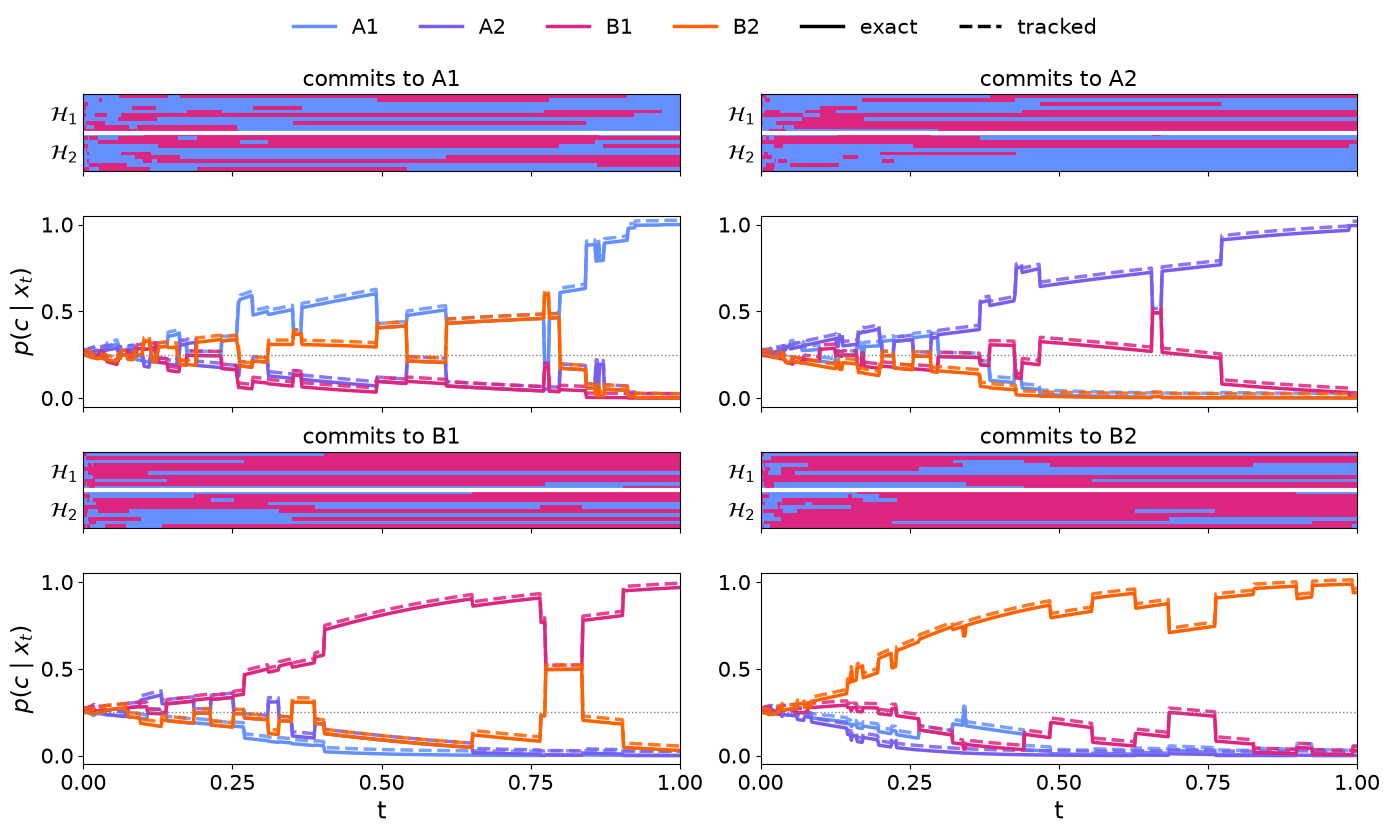

In [16]:
POSTERIOR_BATCH_SIZE = 32     # large enough that every class shows up at least once
POSTERIOR_SEED       = 0

posterior_results = run_gt_sampling(unconditional_analytic_denoiser,
                                    batch_size=POSTERIOR_BATCH_SIZE, seed=POSTERIOR_SEED)
_, exact_posts, tracked_posts, _ = posterior_results
final_class = exact_posts[-1].argmax(dim=-1)
print(f'NOISE_TYPE={NOISE_TYPE!r}   mean |tracked - exact| = '
      f'{(tracked_posts - exact_posts).abs().mean().item():.2e}')
print('trajectories per class:',
      {CLASS_NAMES[c]: int((final_class == c).sum()) for c in range(NUM_CLASSES)})

sample_ids = one_trajectory_per_class(exact_posts)
assert None not in sample_ids, 'raise POSTERIOR_BATCH_SIZE: some class has no trajectory'
_ = plot_posterior_grid(posterior_results, sample_ids,
                        savefig_title='posterior_4classes_unconditional')

## AND

AND$(c_1, c_2)$ is multiplicative: the target is the product of the two class distributions,
taken at the **data level**,
$p_{\mathrm{AND}}(x_1) \propto p(x_1\mid c_1)\,p(x_1\mid c_2)$. Its exact form is a property of
the clean distributions alone — the product of two i.i.d.-per-position laws is another one, so

$$Q_{\mathrm{AND}}[j] = \frac{Q[c_1,j]\,Q[c_2,j]}{Q[c_1,j]\,Q[c_2,j] + (1-Q[c_1,j])(1-Q[c_2,j])}.$$

**The predictor is not just the sum of the conditional logits.** Writing the product in terms of
what the model gives at time $t$,

$$\log p(x_1\mid x_t) = \sum_{i=1}^{N} \log p(x_1\mid x_t, c_i) + (1 - N)\log p_t(x_t\mid x_1),$$

the extra term appears because each of the $N$ conditionals already carries the forward kernel
once, while the target should carry it only once in total. Under masking
$p_t(x_t^j\mid x_1^j)$ does not depend on $x_1^j$ — a revealed position is an exact copy — so the
term is constant across tokens and drops out of the softmax. Under uniform noise
$p_t(x_t^j\mid x_1^j = a) = \kappa_t\,\mathbb{1}[x_t^j = a] + (1-\kappa_t)/V$ *does* depend on the
token, and dropping it double-counts the corruption. It involves only the forward kernel, so it is
known exactly, without the model. OR and NOT are weighted averages and need no such term.

In [17]:
def and_ground_truth_Q(class_ids):
    """Exact per-position law Q_AND[j] of the data-level product mixture
    p_AND(x_0) propto prod_i p(x_0|c_i). Each class is i.i.d.-per-position, so the product is
    too -- Bernoullis at a fixed position simply multiply and renormalise. Purely a property of
    the clean data distributions, independent of the noise model."""
    Qs = Q[list(class_ids)]                # [K, L]
    num = Qs.prod(dim=0)
    den = num + (1 - Qs).prod(dim=0)
    return num / den.clamp(min=1e-12)


def and_discrete(x_preds, x_t, ts, eps=1e-8):
    """Data-level AND: sum the conditional logits, add the (1-N) log p_t(x_t|x_1) correction, and
    renormalise. Under masking that correction is constant in x_1 and cancels in the softmax, so
    this reduces to the plain sum of logits; under uniform noise it is what makes the gate exact."""
    logits = sum(torch.log(p[..., :2].clamp(min=eps)) for p in x_preds)
    if NOISE_TYPE != 'masking':
        kappa = get_scheduler(ts, SCHEDULER_TYPE)[0].view(-1, 1, 1)
        q = kappa * to_one_hot(x_t, VOCAB_SIZE) + (1 - kappa) / VOCAB_SIZE    # p(x_t^j | x_1^j=a), [B, L, 2]
        logits = logits + (1 - len(x_preds)) * torch.log(q.clamp(min=eps))
    combined = torch.zeros_like(x_preds[0])
    combined[..., :2] = torch.softmax(logits, dim=-1)
    return combined

## Reducing to half-counts

All classes are exchangeable within a half, so every target here — the AND law, and the mixtures
behind OR and NOT — depends on a sequence only through $(n_1, n_2)$, the number of A-tokens in
each half. That makes the exact target distribution $T(n_1, n_2)$ a small closed-form table, and
the generated distribution a histogram, so the KL between them is cheap and needs far fewer
samples than comparing full sequences.

Two reference curves are drawn alongside each gate:

- the **exact process** — what a perfect sampler's KL to the *clean* target looks like at each $t$,
  which is non-zero before $t = 1$ simply because $x_t$ is still noisy;
- the **finite-sample floor** — the KL two independent draws of the same size from the *same*
  distribution would score. A gate sitting on this floor is indistinguishable from exact.

In [18]:
import math, os, time
from contextlib import contextmanager
import matplotlib.colors as mcolors
import matplotlib.lines as mlines

# ---------------------------------------------------------------- configuration
N_METRIC        = 4096         # samples per (gate, noise type); raise for smoother curves (the joint-KL floor is ~ 120/(2N))
N_CHECKPOINTS   = 20           # noise levels compared: t_k = k / N_CHECKPOINTS, k = 1..N_CHECKPOINTS
KL_KIND         = 'joint'      # 'joint' -> KL over the table p(n1, n2) | 'marginal_mean' -> mean of the two per-half KLs
FLOOR_REPEATS   = 20           # Monte-Carlo repeats for the finite-sample floor
METRIC_SEED     = 1234
UNIFORM_SAMPLING_KERNEL = 'ancestral'   # kernel drawing x_next under uniform noise ('ancestral' | 'dfm'); masking always 'dfm'
UNIFORM_N_TOKENS        = 2             # data tokens under uniform noise (A, B)

METRIC_AND_CLASSES = [0, 3]        # AND(A1, B2)
METRIC_OR_CLASSES  = [0, 2]        # OR(A1, B1)
METRIC_NOT_CLASSES = [0]           # NOT(A1)
# One colour per gate, same hexes as the paper's figures: AND blue, OR red, NOT gold.
GATE_COLORS = {'AND': mcolors.to_rgba('#648fff'), 'OR': mcolors.to_rgba('#dc267f'),
               'NOT': mcolors.to_rgba('#F2A104')}
NOISES = ('masking', 'uniform')
LINESTYLE = {'masking': '-', 'uniform': ':'}          # full = masking, dotted = uniform

H_LEN = HALF1.stop - HALF1.start
assert H_LEN == HALF2.stop - HALF2.start, 'the two halves must have equal length'
NBINS = H_LEN + 1                                      # counts 0..H_LEN


# ---------------------------------------------------------------- both noise types in one run
@contextmanager
def noise_mode(noise_type):
    """Temporarily switch the notebook-wide noise globals (NOISE_TYPE, VOCAB_SIZE, MASK and the two kernels)
    so masking and uniform can be evaluated in ONE execution. Every function of the notebook reads these
    globals at call time, so nothing else needs to change; the previous values are restored on exit."""
    g = globals()
    keys = ('NOISE_TYPE', 'VOCAB_SIZE', 'MASK', 'SAMPLING_KERNEL', 'POSTERIOR_KERNEL')
    saved = {k: g[k] for k in keys}
    masking = noise_type == 'masking'
    try:
        g['NOISE_TYPE'] = noise_type
        g['VOCAB_SIZE'] = 3 if masking else UNIFORM_N_TOKENS
        g['MASK'] = 2 if masking else None
        g['SAMPLING_KERNEL'] = 'dfm' if masking else UNIFORM_SAMPLING_KERNEL
        g['POSTERIOR_KERNEL'] = g['SAMPLING_KERNEL']
        yield
    finally:
        g.update(saved)


# ---------------------------------------------------------------- exact count distributions
def binom_pmf(n, p):
    """Binomial(n, p) pmf on 0..n (float64); p may be exactly 0 or 1."""
    p = torch.as_tensor(p, dtype=torch.float64)
    k = torch.arange(n + 1, dtype=torch.float64)
    coef = torch.tensor([math.comb(n, i) for i in range(n + 1)], dtype=torch.float64)
    return coef * torch.pow(p, k) * torch.pow(1 - p, n - k)


def half_q(Q_vec):
    """(P(A) in HALF1, P(A) in HALF2) of a per-position law -- must be constant within each half."""
    q1, q2 = Q_vec[HALF1], Q_vec[HALF2]
    assert torch.allclose(q1, q1[0].expand_as(q1)) and torch.allclose(q2, q2[0].expand_as(q2)), \
        'law must be constant within each half'
    return q1[0].item(), q2[0].item()


def joint_from_q(q1, q2):
    return torch.outer(binom_pmf(H_LEN, q1), binom_pmf(H_LEN, q2))       # [NBINS, NBINS], indexed (n1, n2)


def mixture_count_pmf(class_ids):
    return sum(joint_from_q(*half_q(Q[c])) for c in class_ids) / len(class_ids)


def target_clean_pmf(spec):
    """Exact clean distribution of (n1, n2) under the gate's target law."""
    kind, ids = spec['kind'], spec['class_ids']
    if kind == 'AND':
        return joint_from_q(*half_q(and_ground_truth_Q(ids)))
    if kind == 'OR':
        return mixture_count_pmf(ids)
    if kind == 'NOT':                                   # uniformly among the OTHER classes
        return mixture_count_pmf([c for c in range(NUM_CLASSES) if c not in ids])
    raise ValueError(kind)


def count_channel(kappa, noise_type):
    """K[n, m] = P(m A's in a noisy half | n A's in the clean half) under the per-position corruption."""
    K = torch.zeros(NBINS, NBINS, dtype=torch.float64)
    kappa = torch.as_tensor(kappa, dtype=torch.float64)
    for n in range(NBINS):
        if noise_type == 'masking':        # each clean A stays revealed w.p. kappa; B / MASK never count as A
            K[n, :n + 1] = binom_pmf(n, kappa)
        else:                              # clean A -> A w.p. kappa + (1-kappa)/V ; clean B -> A w.p. (1-kappa)/V
            a = kappa + (1 - kappa) / UNIFORM_N_TOKENS
            b = (1 - kappa) / UNIFORM_N_TOKENS
            K[n] = torch.from_numpy(np.convolve(binom_pmf(n, a).numpy(), binom_pmf(H_LEN - n, b).numpy()))
    return K


def noisy_pmf(P1, kappa, noise_type):
    """Exact distribution of (n1, n2) of x_t: the clean table pushed through the channel on each half."""
    K = count_channel(kappa, noise_type)
    return K.T @ P1 @ K


# ---------------------------------------------------------------- KL on count tables
def _kl(p, q, eps=1e-12):
    p = p / p.sum(); q = q / q.sum()
    m = p > 0
    return (p[m] * torch.log(p[m] / q[m].clamp(min=eps))).sum().item()


def kl_counts(p, q, kind=None):
    """KL(p || q) between two [NBINS, NBINS] tables (p empirical / first argument)."""
    kind = KL_KIND if kind is None else kind
    if kind == 'joint':
        return _kl(p.flatten(), q.flatten())
    return 0.5 * (_kl(p.sum(1), q.sum(1)) + _kl(p.sum(0), q.sum(0)))


def count_hist(x):
    n1 = (x[:, HALF1] == 0).sum(-1)
    n2 = (x[:, HALF2] == 0).sum(-1)
    return torch.bincount(n1 * NBINS + n2, minlength=NBINS * NBINS).view(NBINS, NBINS).double()


# ---------------------------------------------------------------- lean sampler: only the count table at the checkpoints
def gate_pred_fn(kind, class_ids):
    """The combined prediction x_pred(x, ts) of a gate, using the exact posterior to weight
    the conditional denoisers for OR and NOT."""
    if kind == 'AND':
        def f(x, ts):
            preds = [class_conditional_analytic_denoiser(x, ts, class_id=c)[0] for c in class_ids]
            return and_discrete(preds, x, ts)
        return f
    if kind == 'OR':
        def f(x, ts):
            post = analytic_class_posterior(x, ts)
            w = post[:, class_ids]
            w = w / w.sum(-1, keepdim=True).clamp(min=1e-8)
            preds = [class_conditional_analytic_denoiser(x, ts, class_id=c)[0] for c in class_ids]
            return sum(w[:, k].view(-1, 1, 1) * preds[k] for k in range(len(class_ids)))
        return f
    if kind == 'NOT':
        def f(x, ts):
            x_pred_uncond, post = unconditional_analytic_denoiser(x, ts)
            x_pred_c = class_conditional_analytic_denoiser(x, ts, class_id=class_ids[0])[0]
            p_c = post[:, class_ids[0]].view(-1, 1, 1)
            scale = p_c / (1.0 - p_c + 1e-8)
            return (x_pred_uncond - scale * (x_pred_c - x_pred_uncond)).clamp(min=0)
        return f
    raise ValueError(kind)


def checkpoint_indices(num_steps, n_checkpoints=N_CHECKPOINTS):
    return sorted({round(k / n_checkpoints * (num_steps - 1)) for k in range(1, n_checkpoints + 1)})


def run_gate_counts(pred_fn, n_samples, seed, num_steps=num_steps, n_checkpoints=N_CHECKPOINTS):
    """Sample n_samples trajectories with the given gate and return (t at checkpoints [K], count tables
    [K, NBINS, NBINS]). Same RNG order as the run_* functions above, but nothing else is stored."""
    torch.manual_seed(seed)
    t_axis = torch.linspace(0, 1, num_steps)
    ck = checkpoint_indices(num_steps, n_checkpoints)
    x = init_state(n_samples)
    hists = []
    for step, (t, t_next) in enumerate(zip(t_axis[:-1], t_axis[1:])):
        ts = t * torch.ones(n_samples)
        x = denoising_step(pred_fn(x, ts), x, t_next, t, VOCAB_SIZE, scheduler_type=SCHEDULER_TYPE)
        if step + 1 in ck:
            hists.append(count_hist(x))
    return t_axis[ck], torch.stack(hists)


# ---------------------------------------------------------------- gate registry, sampling and analysis
def _cname(c):
    n = CLASS_NAMES[c]
    return f'{n[0]}_{{{n[1:]}}}' if len(n) > 1 else n


def _finish_specs(specs):
    for sp in specs:
        names = ','.join(_cname(c) for c in sp['class_ids'])
        sp['title'] = rf"{sp['kind']}$({names})$"
        sp['label'] = sp['title']
        sp['color'] = GATE_COLORS[sp['kind']]
    return specs


def build_gate_specs():
    return _finish_specs([
        dict(kind='AND', class_ids=METRIC_AND_CLASSES),
        dict(kind='OR',  class_ids=METRIC_OR_CLASSES),
        dict(kind='NOT', class_ids=METRIC_NOT_CLASSES),
    ])


def run_all_gate_counts(specs, n_samples=None, seed=METRIC_SEED):
    n_samples = N_METRIC if n_samples is None else n_samples          # looked up at call time
    results = {}
    for spec in specs:
        for noise in NOISES:
            with noise_mode(noise):
                t0 = time.time()
                t_ck, hist = run_gate_counts(gate_pred_fn(spec['kind'], spec['class_ids']),
                                             n_samples, seed)
                results[(spec['label'], noise)] = dict(t=t_ck, hist=hist)
                print(f"  {spec['kind']:3s} {noise:8s} {spec['label']:32s} {time.time() - t0:5.1f}s")
    return results


def analyse_gate_counts(results, specs, seed=METRIC_SEED + 1):
    """Turn the count tables into the curves that are plotted (all KLs use KL_KIND)."""
    torch.manual_seed(seed)
    curves = {}
    for spec in specs:
        P1 = target_clean_pmf(spec)
        for noise in NOISES:
            r_ = results[(spec['label'], noise)]
            kappas = get_scheduler(r_['t'], SCHEDULER_TYPE)[0]
            P_t = [noisy_pmf(P1, k, noise) for k in kappas]
            ref_clean = np.array([kl_counts(p, P1) for p in P_t])                      # exact process vs clean target
            floor = np.zeros((len(P_t), FLOOR_REPEATS))                                 # N draws from P_t vs P_t
            for k, p in enumerate(P_t):
                for r in range(FLOOR_REPEATS):
                    draw = torch.multinomial(p.flatten(), N_METRIC, replacement=True)
                    h = torch.bincount(draw, minlength=NBINS * NBINS).view(NBINS, NBINS).double()
                    floor[k, r] = kl_counts(h, p)
            curves[(spec['label'], noise)] = dict(
                t=r_['t'].numpy(),
                vs_clean=np.array([kl_counts(h, P1) for h in r_['hist']]),
                vs_marginal=np.array([kl_counts(h, p) for h, p in zip(r_['hist'], P_t)]),
                ref_clean=ref_clean, floor_mean=floor.mean(1),
                floor_lo=np.percentile(floor, 5, axis=1), floor_hi=np.percentile(floor, 95, axis=1))
    return curves


def print_metric_summary(curves, specs):
    """excess = mean_t KL(gen || exact marginal) / mean_t floor; ~1 means indistinguishable from an exact sampler."""
    print(f'{"gate":34s} {"noise":8s} {"excess over floor":>18s} {"KL vs clean @t=1":>17s}')
    for spec in specs:
        for noise in NOISES:
            c = curves[(spec['label'], noise)]
            print(f'{spec["kind"] + " " + spec["label"]:34s} {noise:8s} '
                  f'{c["vs_marginal"].mean() / c["floor_mean"].mean():18.2f} {c["vs_clean"][-1]:17.4f}')

## Sampling every gate, under both noise types

Each run stores only the $(n_1, n_2)$ table at the checkpoints, so raising `N_METRIC` costs
little memory; runtime is dominated by the sampling steps. `excess over floor` in the summary is
the mean KL to the exact noised marginal divided by the mean finite-sample floor — about 1 means
the gate is indistinguishable from an exact sampler.

In [19]:
GATE_SPECS = build_gate_specs()
t_start = time.time()
METRIC_RESULTS = run_all_gate_counts(GATE_SPECS)
print(f'sampling finished in {time.time() - t_start:.0f}s  ({N_METRIC} samples per run, {N_CHECKPOINTS} checkpoints)')
METRIC_CURVES = analyse_gate_counts(METRIC_RESULTS, GATE_SPECS)
print_metric_summary(METRIC_CURVES, GATE_SPECS)

  AND masking  AND$(A_{1},B_{2})$                11.8s
  AND uniform  AND$(A_{1},B_{2})$                14.3s
  OR  masking  OR$(A_{1},B_{1})$                  9.6s
  OR  uniform  OR$(A_{1},B_{1})$                 12.7s
  NOT masking  NOT$(A_{1})$                      10.9s
  NOT uniform  NOT$(A_{1})$                      15.3s
sampling finished in 75s  (4096 samples per run, 20 checkpoints)
gate                               noise     excess over floor  KL vs clean @t=1
AND AND$(A_{1},B_{2})$             masking                0.98            0.0078
AND AND$(A_{1},B_{2})$             uniform                1.02            0.0056
OR OR$(A_{1},B_{1})$               masking                1.02            0.0123
OR OR$(A_{1},B_{1})$               uniform                1.03            0.0176
NOT NOT$(A_{1})$                   masking                1.06            0.0147
NOT NOT$(A_{1})$                   uniform                0.95            0.0136


## Figure — AND, OR and NOT approach their targets

KL between the half-count distribution of the noisy state $x_t$ and that of the clean target, for
AND(`A1`,`B2`), OR(`A1`,`B1`) and NOT(`A1`), under masking (full) and uniform (dotted) noise.

Each curve starts high — at $t=0$ the state is pure noise and nothing matches the target — and
decays onto the grey exact-process reference, reaching the sampling-noise floor at $t=1$. That
the generated and reference curves meet is the statement that the derived gates really do sample
from the intended distribution.

In [20]:
def _pos(a):                                            # keep log-scale plots finite
    return np.maximum(a, 1e-6)


def _ref(a):                                            # exact-process KL reaches exactly 0 at t=1: drop it so the log axis is not stretched
    return np.where(a > 1e-4, a, np.nan)


def _ylabel():
    return r'KL over $(n_1,n_2)$' if KL_KIND == 'joint' else r'mean KL over $n_1,\ n_2$'


def plot_gate_evolution_big(curves, specs, which='vs_clean', overlay=False, show_reference=True,
                            fontsize=22, savefig_title=None):
    """Big figure: AND / OR / NOT next to each other (overlay=True: all three on one axis). Colours: AND blue,
    OR red, NOT gold, as in the paper's figures. Full line = masking, dotted = uniform."""
    big = [next(s for s in specs if s['kind'] == k) for k in ('AND', 'OR', 'NOT')]
    if overlay:
        fig, ax0 = plt.subplots(figsize=(11, 7.5)); axes = [ax0] * 3
    else:
        fig, axes = plt.subplots(1, 3, figsize=(24, 7.5), sharey=True)
    for ax, spec in zip(axes, big):
        for noise in NOISES:
            cv = curves[(spec['label'], noise)]
            if show_reference and not overlay and which == 'vs_clean':
                ax.plot(cv['t'], _ref(cv['ref_clean']), color='0.7', lw=2.0, ls=LINESTYLE[noise], zorder=1)
            ax.plot(cv['t'], _pos(cv[which]), color=spec['color'], ls=LINESTYLE[noise], lw=4.5,
                    marker='o', ms=7, zorder=3, label=spec['title'] if (overlay and noise == 'masking') else None)
        ax.set_yscale('log')
        ax.tick_params(labelsize=fontsize)
        ax.set_xlabel('t', fontsize=fontsize)
        if not overlay:
            ax.set_title(spec['title'], fontsize=fontsize + 2, color=spec['color'][:3])
    axes[0].set_ylabel(_ylabel(), fontsize=fontsize)
    handles = [mlines.Line2D([], [], color='0.2', lw=4.5, ls='-', label='masking'),
               mlines.Line2D([], [], color='0.2', lw=4.5, ls=':', label='uniform')]
    if overlay:
        handles = [mlines.Line2D([], [], color=s['color'], lw=4.5, label=s['title']) for s in big] + handles
    elif show_reference and which == 'vs_clean':
        handles.append(mlines.Line2D([], [], color='0.7', lw=2.0, label='exact process'))
    fig.legend(handles=handles, loc='upper center', ncol=len(handles), fontsize=fontsize - 2, frameon=False,
               bbox_to_anchor=(0.5, 1.02))
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    if savefig_title is not None:
        os.makedirs(FIG_DIR, exist_ok=True)
        plt.savefig(f'{FIG_DIR}/{savefig_title}.pdf', format='pdf', bbox_inches='tight')
    plt.show()
    return fig

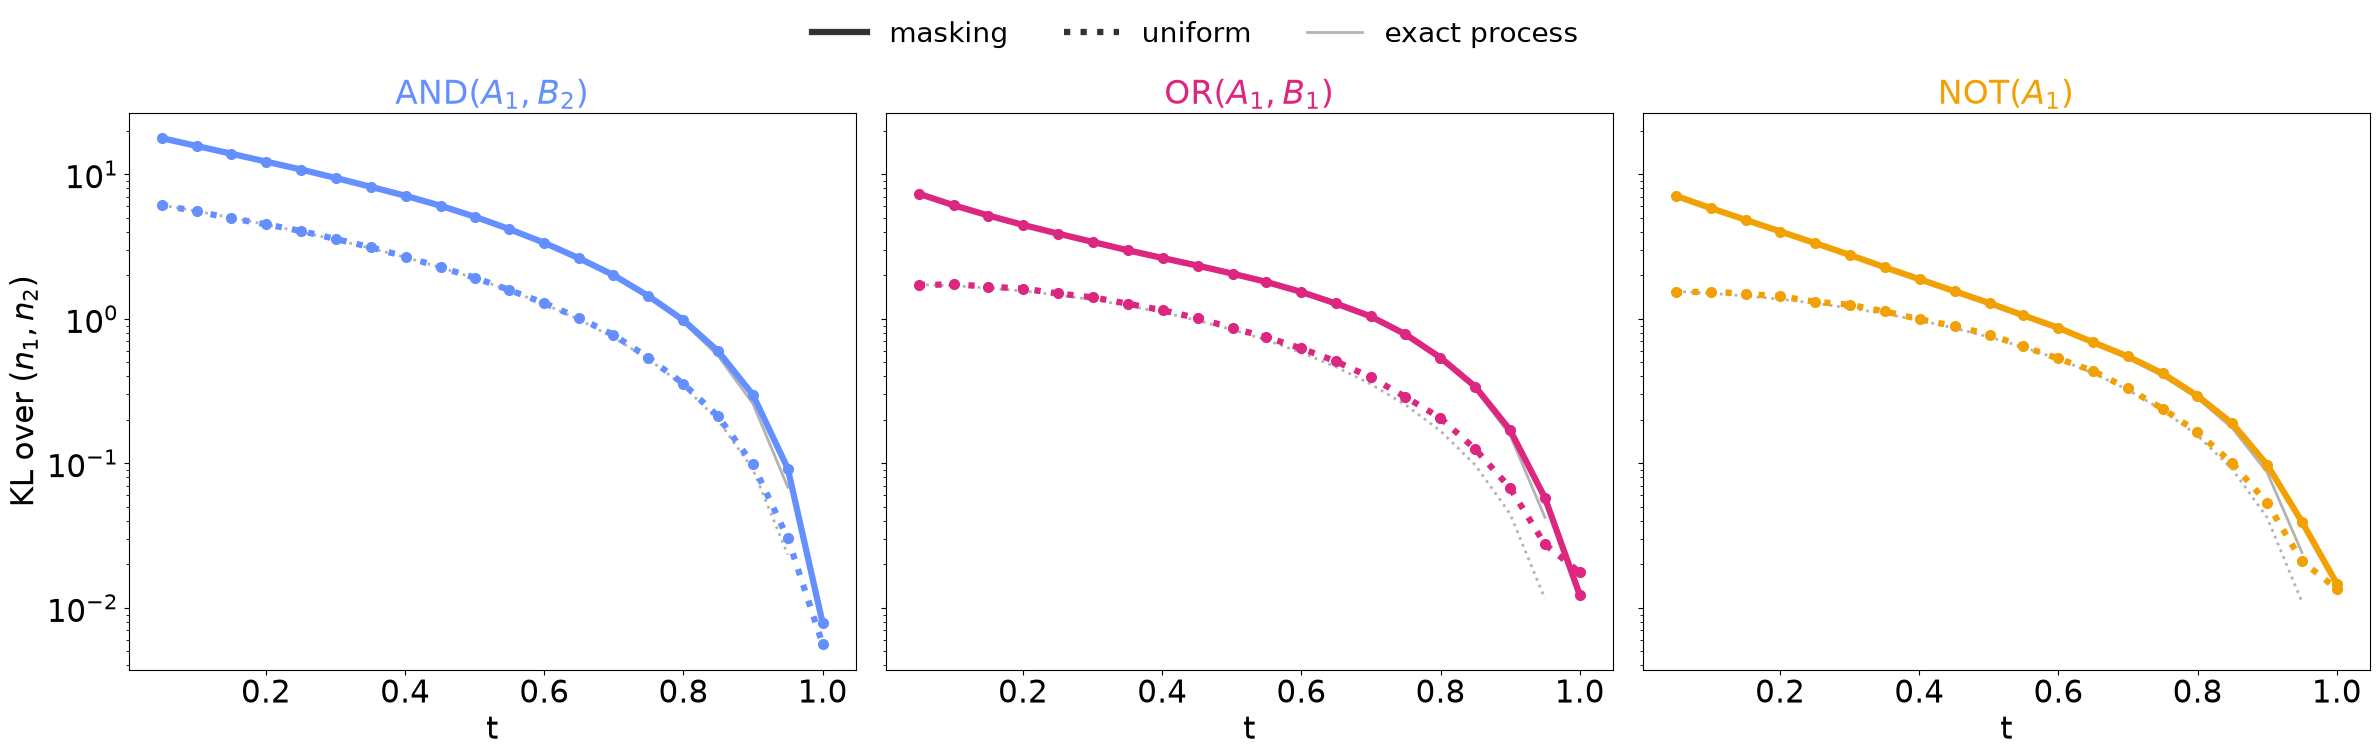

In [21]:
# Big figure -- evolution of AND, OR and NOT next to each other (blue / red / gold, as in figures_for_the_paper.ipynb)
fig_big = plot_gate_evolution_big(METRIC_CURVES, GATE_SPECS, which='vs_clean',
                                  savefig_title='analytic_gates_evolution_AND_OR_NOT')